# OLYMPUS TECH 4.0  Part Two Data Analysis


In [ ]:
# Run this once in a fresh Google Colab session.
!pip -q install pandas numpy matplotlib seaborn scipy

## Setup

Load the cleaned dataset and define a few reusable helpers for averages, uncertainty bars and plot styling.

In [2]:
"""Generate the Task 2 written analysis and its supporting plots.

Run from the repository root:
    python olympus_part2/task2_analysis.py

Required packages:
    pandas, numpy, matplotlib, seaborn, scipy
"""

from __future__ import annotations

import json
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr


TEAM = "The gentlemen"
# Find the cleaned dataset whether this notebook is run in the repository or in Colab.
_candidates = [
    Path.cwd() / "outputs" / f"{TEAM}_cleaned_dataset.csv",
    Path.cwd() / f"{TEAM}_cleaned_dataset.csv",
    Path.cwd() / "olympus_part2" / "outputs" / f"{TEAM}_cleaned_dataset.csv",
]
DATA_PATH = next((p for p in _candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Upload {TEAM}_cleaned_dataset.csv or run this notebook from the olympus_part2 folder."
    )
ROOT = DATA_PATH.parent.parent if DATA_PATH.parent.name == "outputs" else Path.cwd()
PLOT_DIR = ROOT / "task2_solution_plots"
REPORT_PATH = ROOT / f"{TEAM}_task2_solution.md"
NOTEBOOK_PATH = ROOT / f"{TEAM}_notebook_analysis.ipynb"
SUMMARY_PATH = ROOT / "task2_analysis_summary.json"
ZIP_PATH = ROOT / f"{TEAM}_Task2_Analysis_Deliverables.zip"

PLOT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "savefig.dpi": 180,
        "font.family": "DejaVu Sans",
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
    }
)

COLORS = {
    "navy": "#25445f",
    "teal": "#2a9d8f",
    "gold": "#e9c46a",
    "orange": "#f4a261",
    "red": "#d65a4a",
    "gray": "#82909c",
    "light": "#dbe8e6",
}


def mean_ci(values: pd.Series) -> tuple[float, float]:
    """Mean and approximate 95% confidence half-width."""
    values = values.dropna()
    return float(values.mean()), float(1.96 * values.std(ddof=1) / np.sqrt(len(values)))


def group_summary(df: pd.DataFrame, column: str) -> pd.DataFrame:
    out = (
        df.groupby(column, observed=True)["settlement_index"]
        .agg(["count", "mean", "median", "std"])
        .reset_index()
    )
    out["viable_percent"] = (
        df.assign(_viable=df["settlement_index"] >= 60)
        .groupby(column, observed=True)["_viable"]
        .mean()
        .values
        * 100
    )
    out["ci95"] = 1.96 * out["std"] / np.sqrt(out["count"])
    return out


def save_plot(fig: plt.Figure, filename: str) -> None:
    fig.tight_layout()
    fig.savefig(PLOT_DIR / filename, bbox_inches="tight")
    plt.close(fig)


df = pd.read_csv(DATA_PATH)
assert len(df) == 6400
assert df["settlement_index"].between(0, 100).all()

from IPython.display import Image, display
print(f"Loaded {len(df):,} cleaned planetary records from {DATA_PATH}")

Loaded 6,400 cleaned planetary records from /workspaces/default/code/olympus_part2/outputs/The gentlemen_cleaned_dataset.csv


## Q1. How does the primary hazard relate to settlement potential?

Hazard-free worlds score highest. Temperature extremes, radiation and toxic air are among the least favourable conditions. The very high averages for “none”, seasonal storms and thermal vents should be interpreted carefully because those groups are small.

,primary_hazard,count,mean,viable_percent
0,none,9,83.9,100.0
3,seasonal_storms,3,79.1,100.0
7,thermal_vents,6,73.7,100.0
9,unknown_anomaly,1315,63.9,56.3
5,storms,1285,61.8,52.6
1,predators,279,59.4,42.7
4,seismic,1392,57.2,36.9
8,toxic_air,829,56.1,31.1
2,radiation,1241,55.5,29.9
6,temperature_extremes,41,54.8,29.3


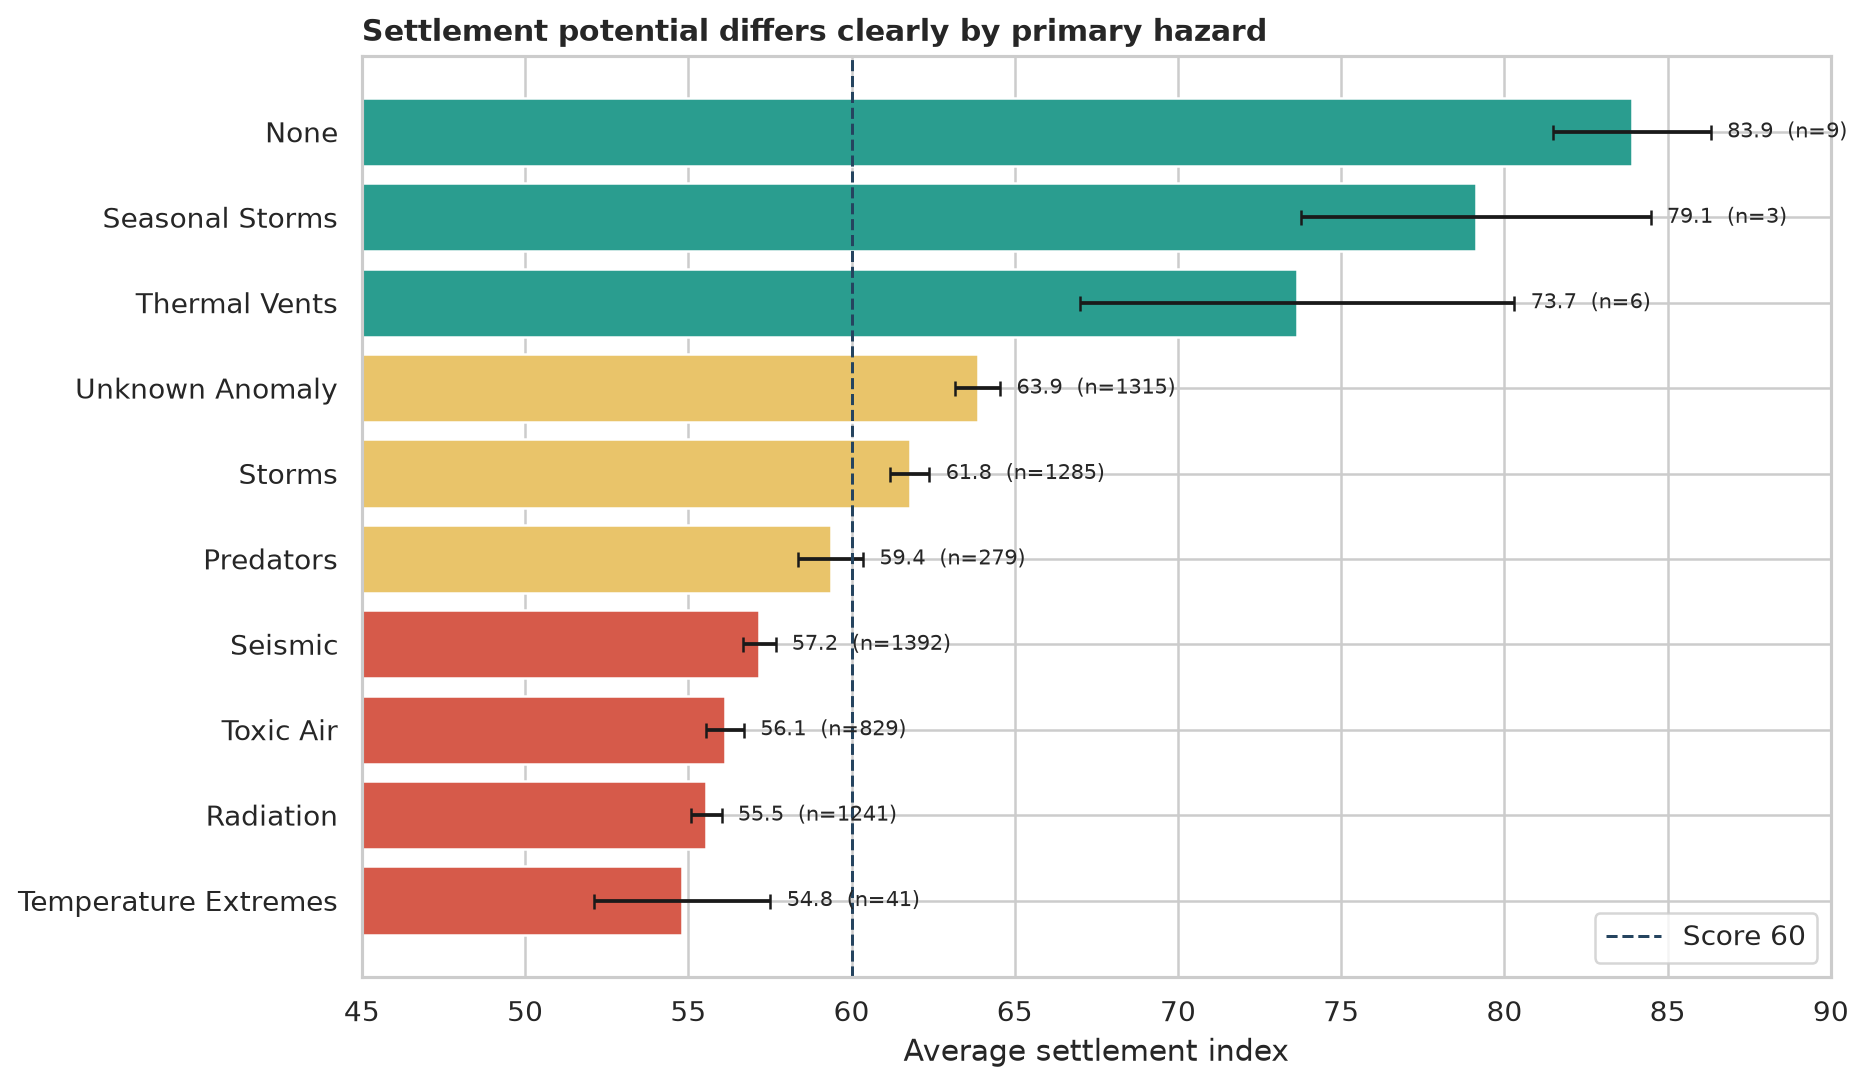

In [3]:
# --------------------------------------------------------------------------------------
# Q1: Primary hazard
# --------------------------------------------------------------------------------------
hazard = group_summary(df, "primary_hazard").sort_values("mean")

fig, ax = plt.subplots(figsize=(10.5, 6.2))
palette = [
    COLORS["red"] if v < 58 else COLORS["gold"] if v < 65 else COLORS["teal"]
    for v in hazard["mean"]
]
ax.barh(
    hazard["primary_hazard"].str.replace("_", " ").str.title(),
    hazard["mean"],
    xerr=hazard["ci95"],
    color=palette,
    capsize=3,
)
for y, (_, row) in enumerate(hazard.iterrows()):
    ax.text(
        row["mean"] + row["ci95"] + 0.5,
        y,
        f'{row["mean"]:.1f}  (n={int(row["count"])})',
        va="center",
        fontsize=8.5,
    )
ax.axvline(60, color=COLORS["navy"], linestyle="--", linewidth=1.2, label="Score 60")
ax.set_xlim(45, 90)
ax.set_xlabel("Average settlement index")
ax.set_ylabel("")
ax.set_title("Settlement potential differs clearly by primary hazard")
ax.legend(loc="lower right")
save_plot(fig, "q1_primary_hazard.png")

display(hazard[["primary_hazard", "count", "mean", "viable_percent"]].sort_values("mean", ascending=False).round(1))
display(Image(filename=str(PLOT_DIR / "q1_primary_hazard.png")))

## Q2. How do atmospheric gases relate to settlement potential?

Moderate oxygen is linked to better scores. Very high carbon dioxide and methane are linked to lower scores. The complete atmospheric mixture matters more than any gas on its own.


 oxygen_percent


,_band,count,mean,viable_percent
0,0–1,3120,53.7,20.8
1,1–10,893,56.9,32.1
2,10–20,1570,67.2,75.7
3,20–25,790,66.9,71.3
4,Above 25,27,65.2,81.5



 co2_percent


,_band,count,mean,viable_percent
0,0–0.5,2482,58.8,40.7
1,0.5–5,1880,63.2,56.9
2,5–20,710,59.2,46.5
3,20–70,296,54.5,24.3
4,Above 70,1032,54.2,22.0



 methane_percent


,_band,count,mean,viable_percent
0,0–0.1,3675,61.2,49.3
1,0.1–1,1378,58.7,42.6
2,1–10,536,55.5,28.5
3,10–50,266,53.7,19.2
4,Above 50,545,53.2,19.3


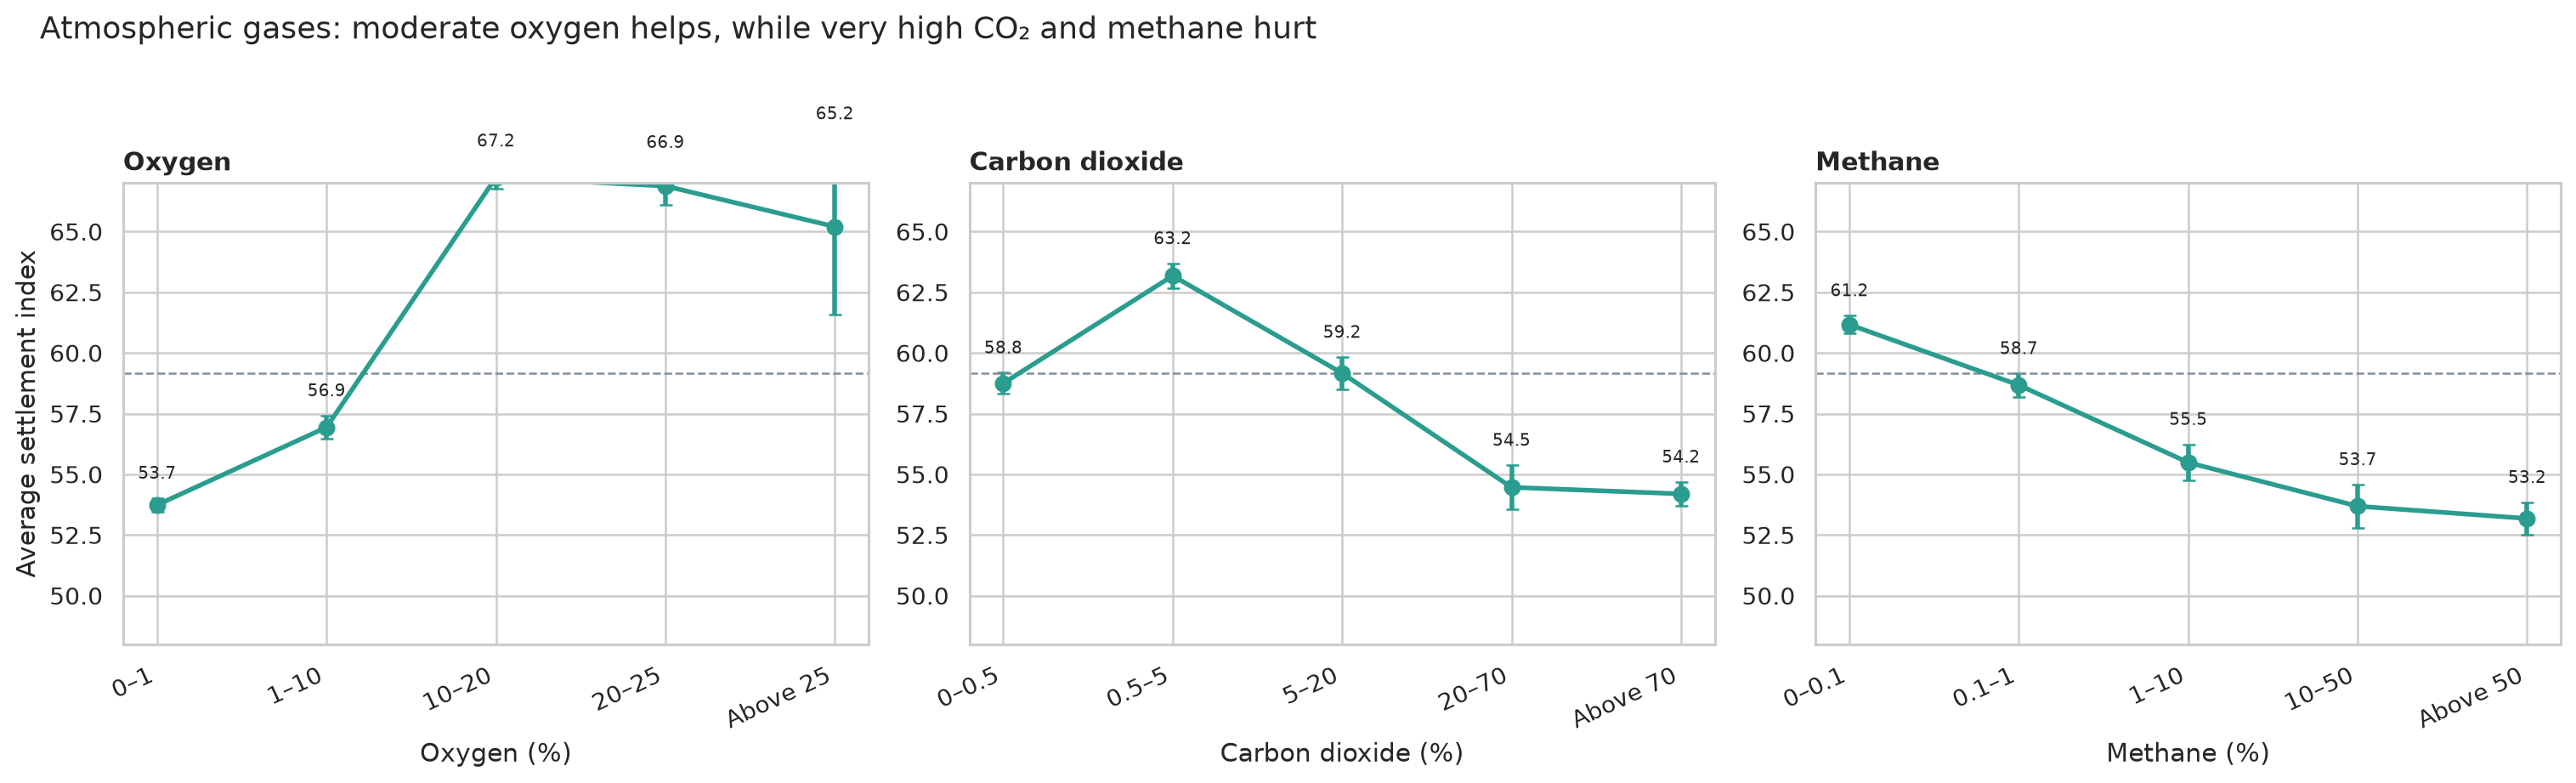

In [4]:
# --------------------------------------------------------------------------------------
# Q2: Atmospheric gases
# --------------------------------------------------------------------------------------
gas_specs = {
    "oxygen_percent": (
        "Oxygen",
        [-np.inf, 1, 10, 20, 25, np.inf],
        ["0–1", "1–10", "10–20", "20–25", "Above 25"],
    ),
    "co2_percent": (
        "Carbon dioxide",
        [-np.inf, 0.5, 5, 20, 70, np.inf],
        ["0–0.5", "0.5–5", "5–20", "20–70", "Above 70"],
    ),
    "methane_percent": (
        "Methane",
        [-np.inf, 0.1, 1, 10, 50, np.inf],
        ["0–0.1", "0.1–1", "1–10", "10–50", "Above 50"],
    ),
}

gas_summaries: dict[str, pd.DataFrame] = {}
gas_correlations: dict[str, dict[str, float]] = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, (column, (label, bins, labels)) in zip(axes, gas_specs.items()):
    band = pd.cut(df[column], bins=bins, labels=labels, include_lowest=True)
    tmp = df.assign(_band=band)
    summary = group_summary(tmp, "_band")
    gas_summaries[column] = summary
    rho, p_value = spearmanr(df[column], df["settlement_index"])
    gas_correlations[column] = {"spearman_r": float(rho), "p_value": float(p_value)}

    ax.errorbar(
        range(len(summary)),
        summary["mean"],
        yerr=summary["ci95"],
        marker="o",
        markersize=7,
        linewidth=2.2,
        color=COLORS["teal"],
        capsize=3,
    )
    for x, (_, row) in enumerate(summary.iterrows()):
        ax.text(x, row["mean"] + row["ci95"] + 0.8, f'{row["mean"]:.1f}', ha="center", fontsize=8)
    ax.axhline(df["settlement_index"].mean(), color=COLORS["gray"], linestyle="--", linewidth=1)
    ax.set_xticks(range(len(summary)), summary["_band"], rotation=25, ha="right")
    ax.set_ylim(48, 67)
    ax.set_xlabel(f"{label} (%)")
    ax.set_title(label)
axes[0].set_ylabel("Average settlement index")
fig.suptitle("Atmospheric gases: moderate oxygen helps, while very high CO₂ and methane hurt", x=0.02, ha="left")
save_plot(fig, "q2_atmospheric_gases.png")

for gas, table in gas_summaries.items():
    print("\n", gas)
    display(table[["_band", "count", "mean", "viable_percent"]].round(1))
display(Image(filename=str(PLOT_DIR / "q2_atmospheric_gases.png")))

## Q3. How does stellar multiplicity relate to settlement potential?

Planets associated with single stars have the strongest average result. Binary, triple and other companion systems score progressively lower in this archive.

,star_system_group,count,mean,viable_percent
2,Single-star,4010,60.1,45.2
0,Binary-star,1841,58.1,39.3
3,Triple-star,306,56.7,33.0
1,Other companion,243,55.7,28.8


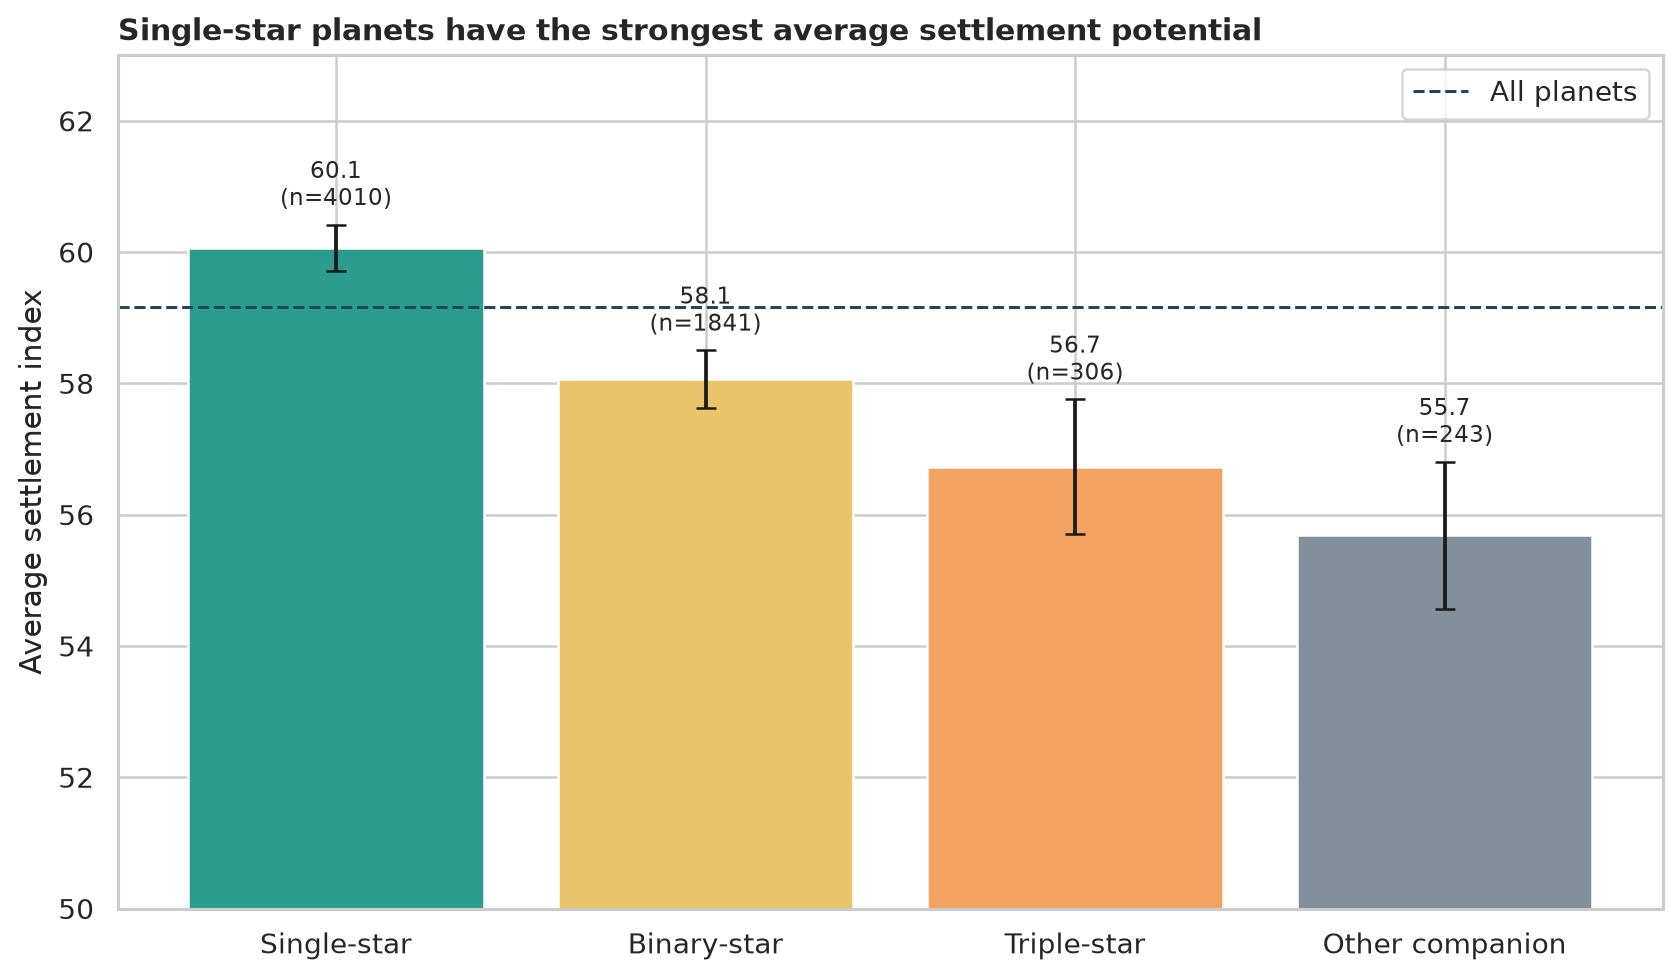

In [5]:
# --------------------------------------------------------------------------------------
# Q3: Stellar multiplicity
# --------------------------------------------------------------------------------------
def star_system_group(star_type: str) -> str:
    low = str(star_type).lower()
    if "triple" in low:
        return "Triple-star"
    if "binary" in low:
        return "Binary-star"
    if "companion" in low:
        return "Other companion"
    return "Single-star"


df["star_system_group"] = df["star_type"].map(star_system_group)
star = group_summary(df, "star_system_group").sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.bar(
    star["star_system_group"],
    star["mean"],
    yerr=star["ci95"],
    color=[COLORS["teal"], COLORS["gold"], COLORS["orange"], COLORS["gray"]],
    capsize=4,
)
for x, (_, row) in enumerate(star.iterrows()):
    ax.text(
        x,
        row["mean"] + row["ci95"] + 0.3,
        f'{row["mean"]:.1f}\n(n={int(row["count"])})',
        ha="center",
        fontsize=9,
    )
ax.axhline(df["settlement_index"].mean(), color=COLORS["navy"], linestyle="--", linewidth=1.2, label="All planets")
ax.set_ylim(50, 63)
ax.set_xlabel("")
ax.set_ylabel("Average settlement index")
ax.set_title("Single-star planets have the strongest average settlement potential")
ax.legend()
save_plot(fig, "q3_stellar_multiplicity.png")

display(star[["star_system_group", "count", "mean", "viable_percent"]].round(1))
display(Image(filename=str(PLOT_DIR / "q3_stellar_multiplicity.png")))

## Q4. How do moons and rings relate to settlement potential?

One- and two-moon planets perform well, but there is no steady trend as moon count rises. Planets without rings score slightly higher than ringed planets.

,moons_count,count,mean
0,0,732,56.6
1,1,1397,62.2
2,2,1884,60.7
3,3,1167,57.3
4,4,683,56.5
5,5,330,56.7
6,6,143,56.9
7,7,44,56.1
8,8,13,55.6
9,9,2,58.0


,rings,count,mean,viable_percent
0,no,5731,59.4,43.1
1,yes,669,56.8,35.4


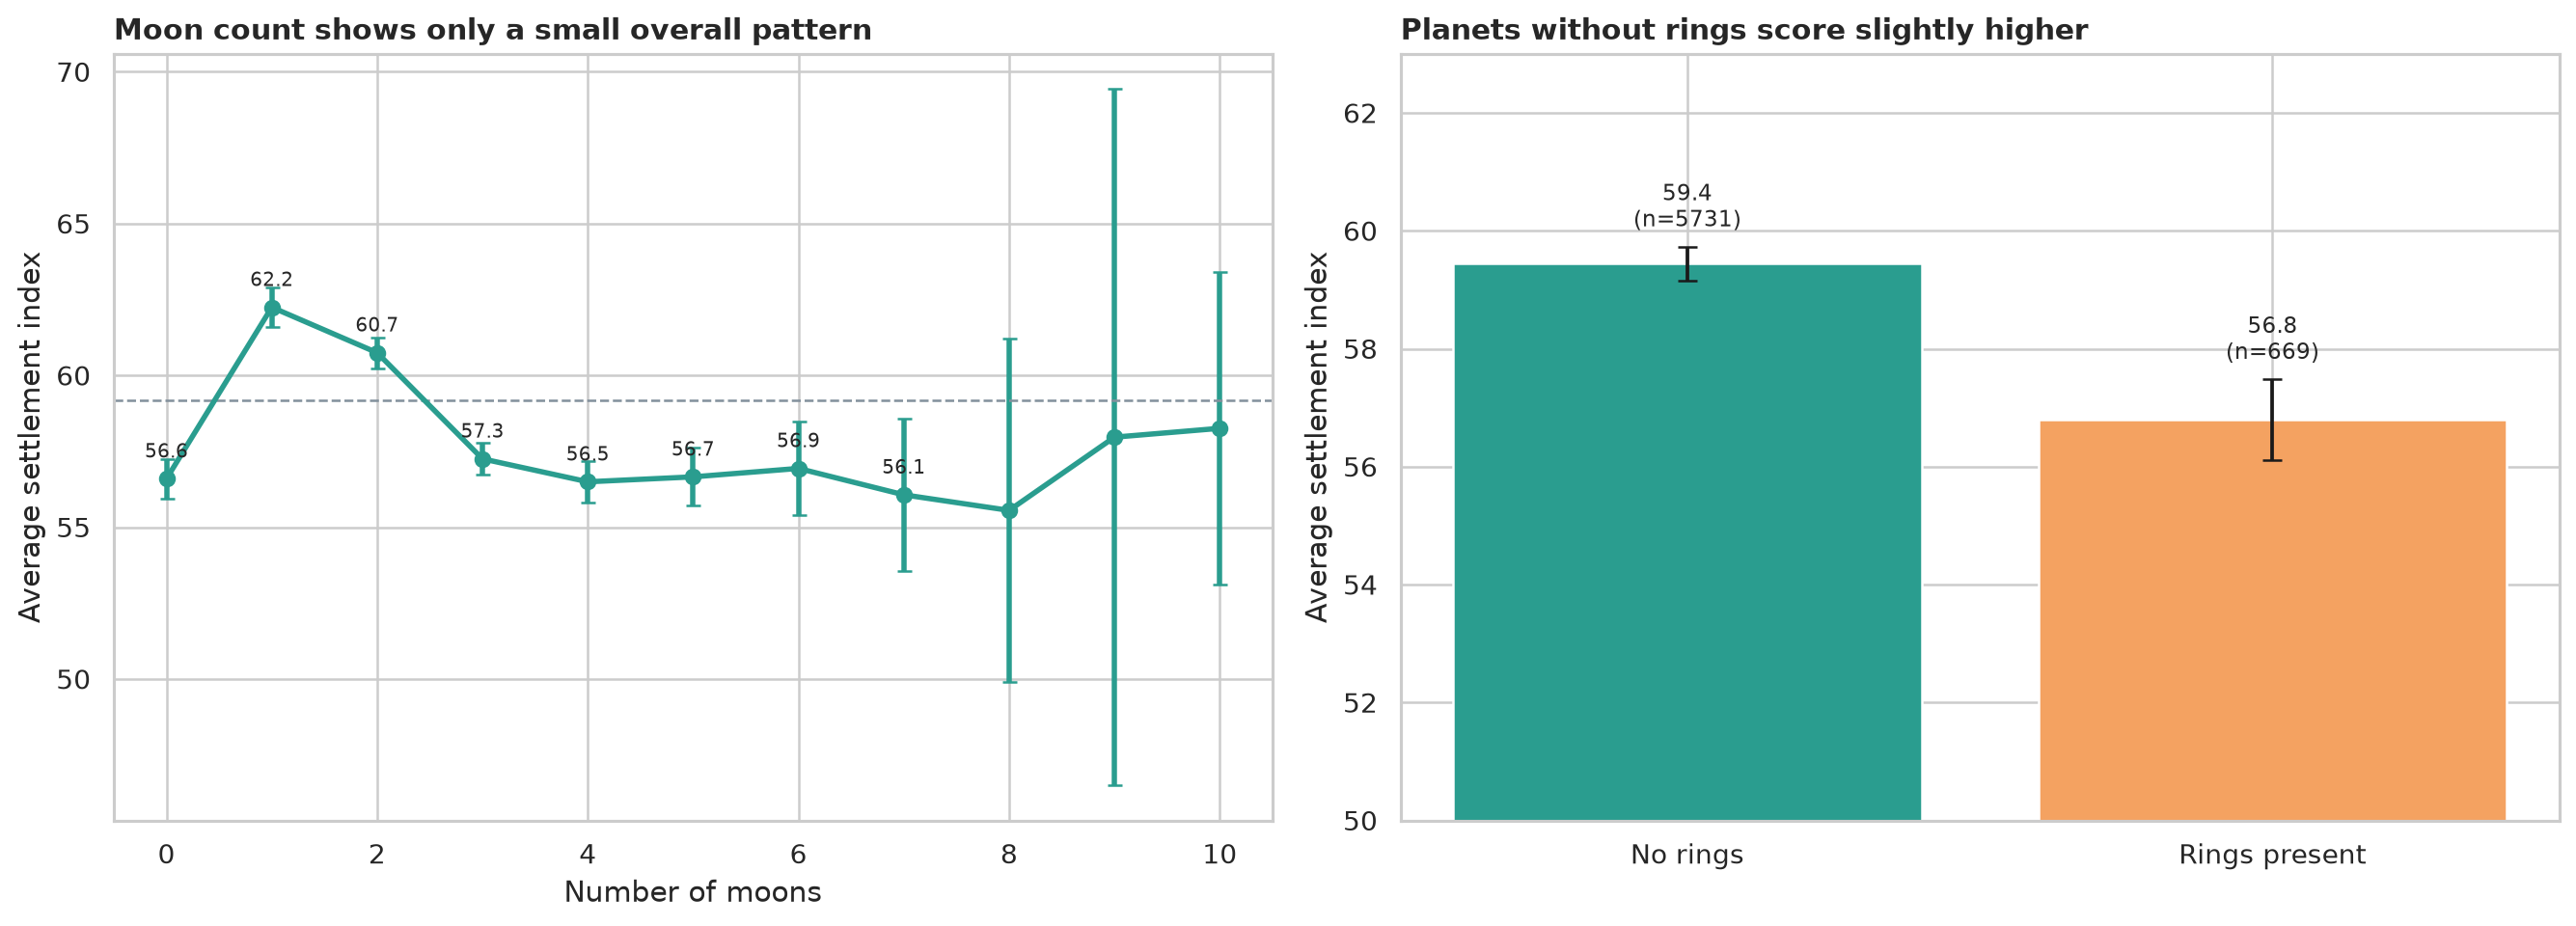

In [6]:
# --------------------------------------------------------------------------------------
# Q4: Moons and rings
# --------------------------------------------------------------------------------------
moon = group_summary(df, "moons_count").sort_values("moons_count")
rings = group_summary(df, "rings").sort_values("mean", ascending=False)
moon_ring = (
    df.groupby(["moons_count", "rings"], observed=True)["settlement_index"]
    .agg(["mean", "count"])
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].errorbar(
    moon["moons_count"],
    moon["mean"],
    yerr=moon["ci95"],
    marker="o",
    linewidth=2.2,
    color=COLORS["teal"],
    capsize=3,
)
for _, row in moon.iterrows():
    if row["count"] >= 20:
        axes[0].text(row["moons_count"], row["mean"] + 0.7, f'{row["mean"]:.1f}', ha="center", fontsize=8)
axes[0].axhline(df["settlement_index"].mean(), color=COLORS["gray"], linestyle="--", linewidth=1)
axes[0].set_xlabel("Number of moons")
axes[0].set_ylabel("Average settlement index")
axes[0].set_title("Moon count shows only a small overall pattern")

axes[1].bar(
    rings["rings"].map({"no": "No rings", "yes": "Rings present"}),
    rings["mean"],
    yerr=rings["ci95"],
    color=[COLORS["teal"], COLORS["orange"]],
    capsize=4,
)
for x, (_, row) in enumerate(rings.iterrows()):
    axes[1].text(
        x,
        row["mean"] + row["ci95"] + 0.35,
        f'{row["mean"]:.1f}\n(n={int(row["count"])})',
        ha="center",
        fontsize=9,
    )
axes[1].set_ylim(50, 63)
axes[1].set_ylabel("Average settlement index")
axes[1].set_title("Planets without rings score slightly higher")
save_plot(fig, "q4_moons_and_rings.png")

display(moon[["moons_count", "count", "mean"]].round(1))
display(rings[["rings", "count", "mean", "viable_percent"]].round(1))
display(Image(filename=str(PLOT_DIR / "q4_moons_and_rings.png")))

## Q5. How do rogue and tidally locked planets compare with other planets?

Both groups trail other planets on average. However, some rogue and tidally locked planets still score well, so neither label is an automatic rejection.

,planet_group,count,mean,viable_percent
0,Other planets,5127,59.8,44.0
1,Rogue planet,537,56.7,33.0
2,Tidally locked,736,56.6,37.1


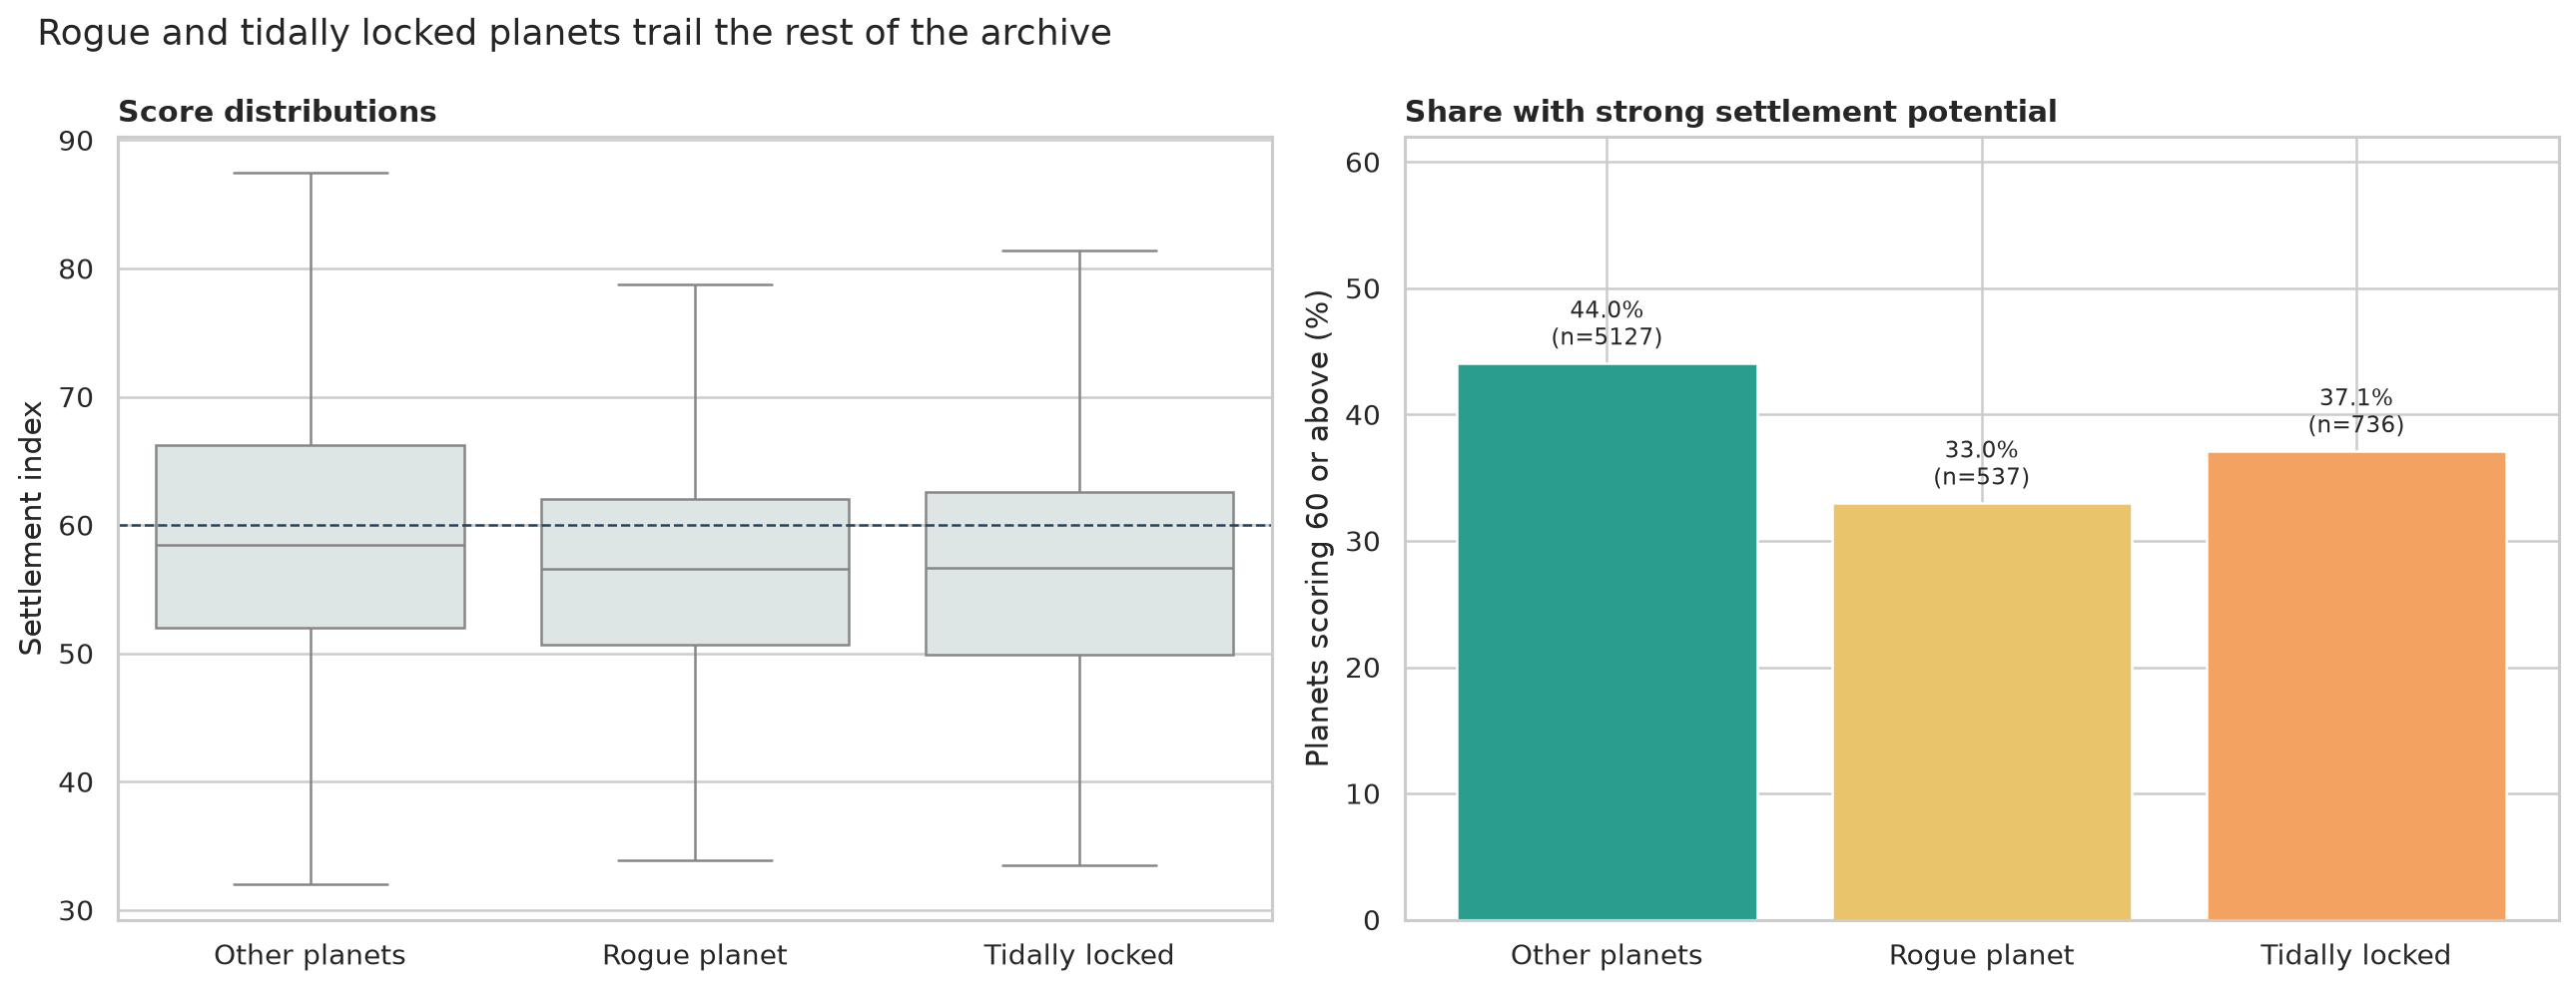

In [7]:
# --------------------------------------------------------------------------------------
# Q5: Rogue, tidally locked and other planets
# --------------------------------------------------------------------------------------
def planet_group(row: pd.Series) -> str:
    if row["planet_type"] == "rogue planet":
        return "Rogue planet"
    if int(row.get("qc_tidally_locked", 0)) == 1 or row["planet_type"] == "tidally locked":
        return "Tidally locked"
    return "Other planets"


df["planet_group"] = df.apply(planet_group, axis=1)
planet = group_summary(df, "planet_group").sort_values("mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6))
order = planet["planet_group"].tolist()
sns.boxplot(
    data=df,
    x="planet_group",
    y="settlement_index",
    order=order,
    ax=axes[0],
    color=COLORS["light"],
    showfliers=False,
)
axes[0].axhline(60, color=COLORS["navy"], linestyle="--", linewidth=1)
axes[0].set_xlabel("")
axes[0].set_ylabel("Settlement index")
axes[0].set_title("Score distributions")

axes[1].bar(
    planet["planet_group"],
    planet["viable_percent"],
    color=[COLORS["teal"], COLORS["gold"], COLORS["orange"]],
)
for x, (_, row) in enumerate(planet.iterrows()):
    axes[1].text(
        x,
        row["viable_percent"] + 1.5,
        f'{row["viable_percent"]:.1f}%\n(n={int(row["count"])})',
        ha="center",
        fontsize=9,
    )
axes[1].set_ylim(0, 62)
axes[1].set_ylabel("Planets scoring 60 or above (%)")
axes[1].set_xlabel("")
axes[1].set_title("Share with strong settlement potential")
fig.suptitle("Rogue and tidally locked planets trail the rest of the archive", x=0.02, ha="left")
save_plot(fig, "q5_rogue_and_tidally_locked.png")

display(planet[["planet_group", "count", "mean", "viable_percent"]].round(1))
display(Image(filename=str(PLOT_DIR / "q5_rogue_and_tidally_locked.png")))

## Independent investigation: Does accessible water improve settlement potential?

Yes. Planets with global oceans or seas have much stronger average scores and far more candidates scoring 60 or above than dry or frozen worlds.

,water_presence,count,mean,viable_percent
0,global ocean,1406,65.4,65.2
3,seas,1676,63.8,62.2
4,subsurface,1893,55.5,27.5
5,trace,694,54.4,21.8
2,none,721,50.5,10.5
1,ice,10,47.9,10.0


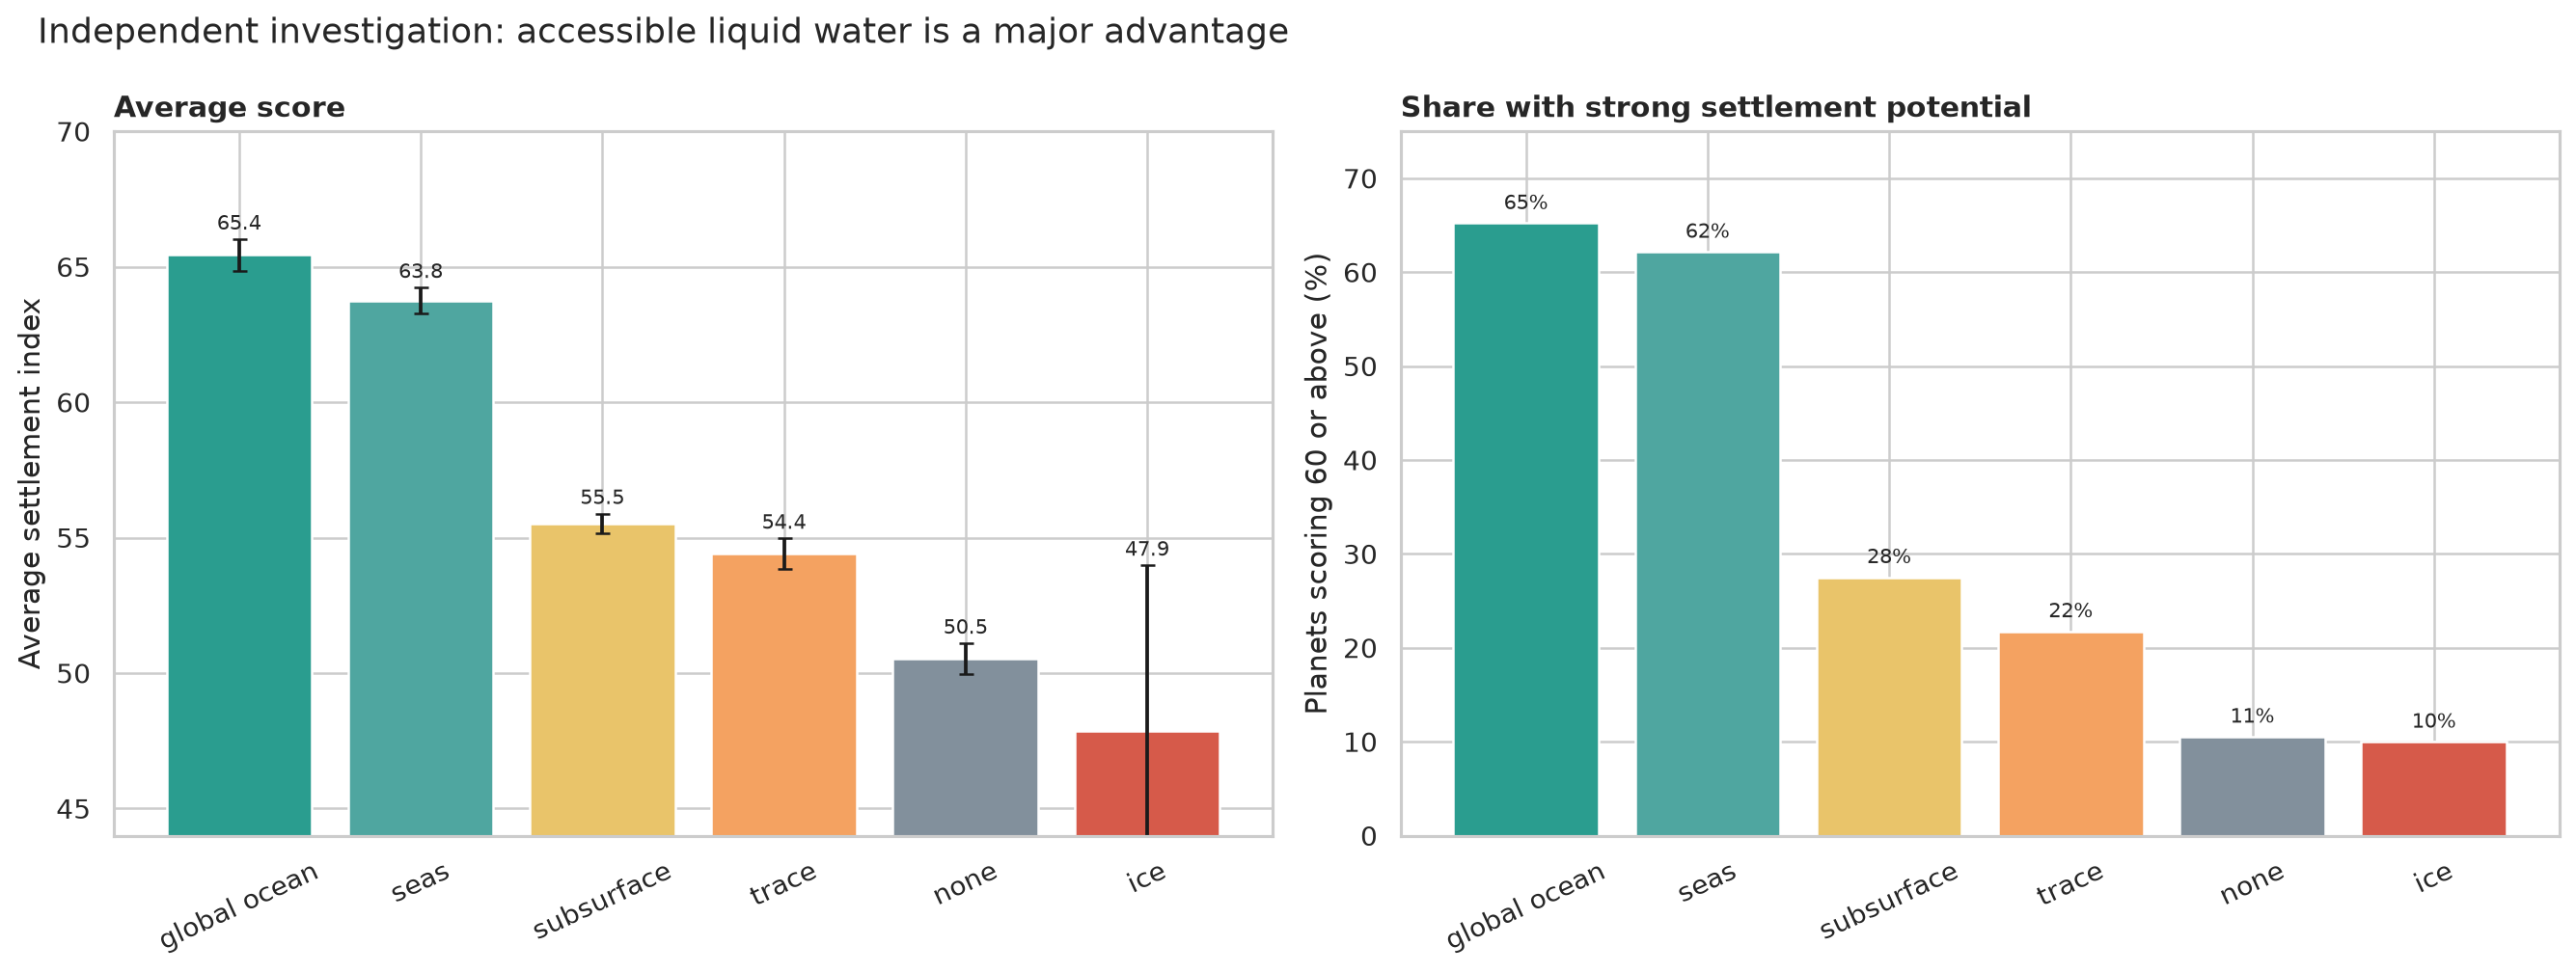

In [8]:
# --------------------------------------------------------------------------------------
# Independent investigation: water availability
# --------------------------------------------------------------------------------------
water = group_summary(df, "water_presence").sort_values("mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.7))
axes[0].bar(
    water["water_presence"],
    water["mean"],
    yerr=water["ci95"],
    color=[COLORS["teal"], "#4fa6a0", COLORS["gold"], COLORS["orange"], COLORS["gray"], COLORS["red"]],
    capsize=3,
)
for x, (_, row) in enumerate(water.iterrows()):
    axes[0].text(x, row["mean"] + row["ci95"] + 0.35, f'{row["mean"]:.1f}', ha="center", fontsize=8.5)
axes[0].set_ylim(44, 70)
axes[0].set_ylabel("Average settlement index")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)
axes[0].set_title("Average score")

axes[1].bar(
    water["water_presence"],
    water["viable_percent"],
    color=[COLORS["teal"], "#4fa6a0", COLORS["gold"], COLORS["orange"], COLORS["gray"], COLORS["red"]],
)
for x, (_, row) in enumerate(water.iterrows()):
    axes[1].text(x, row["viable_percent"] + 1.5, f'{row["viable_percent"]:.0f}%', ha="center", fontsize=8.5)
axes[1].set_ylim(0, 75)
axes[1].set_ylabel("Planets scoring 60 or above (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=25)
axes[1].set_title("Share with strong settlement potential")
fig.suptitle("Independent investigation: accessible liquid water is a major advantage", x=0.02, ha="left")
save_plot(fig, "independent_water_availability.png")

display(water[["water_presence", "count", "mean", "viable_percent"]].round(1))
display(Image(filename=str(PLOT_DIR / "independent_water_availability.png")))

## Final conclusion

The strongest settlement candidates combine several advantages: manageable hazards, accessible liquid water, a moderate atmosphere and a relatively stable stellar environment. No single feature guarantees a high score.